In [1]:
import geopandas as gpd
import geopandas as gpd
from shapely.ops import unary_union, polygonize
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.stats import linregress

In [2]:
points = gpd.read_file("/Volumes/MaloneLab/Research/Whitezone/Result/Spatial_Modelling/Results/combined_hydro.shp")
# Ensure CRS is geographic (lat/lon), if not reproject to WGS84
if points.crs != "EPSG:4326":
    points = points.to_crs("EPSG:4326")

# Extract lat/lon
points["lon"] = points.geometry.x
points["lat"] = points.geometry.y

# Now you have a DataFrame with lat/lon
print(points[["lat", "lon"]].head())

# 2. Read transects shapefile
transects = gpd.read_file("/Volumes/MaloneLab/Research/Whitezone/Spatial_Data/transects_39_61.shp")

# Reproject if needed to match CRS
if transects.crs != "EPSG:4326":
    transects = transects.to_crs("EPSG:4326")

print(transects.head())

         lat        lon
0  25.175889 -80.735583
1  25.175556 -80.792778
2  25.224566 -80.540061
3  25.232625 -80.524867
4  25.198611 -80.618879
   ID                                           geometry
0  39  LINESTRING (-80.43141 25.24549, -80.47312 25.3...
1  61  LINESTRING (-80.51986 25.22790, -80.55485 25.2...


In [3]:
west = [
    "NP-P37", 
    "NP-146", 
    "Upstream_Taylor", 
    "NP-OL", 
    "Mud_Creek_at_mouth", 
    "SWEVER5A"
]

central = [
    "G-1251", 
    "EVER7", 
    "CT50R", 
    "EVER6", 
    "NP-EPSW", 
    "EPSW", 
    "CV5NR", 
    "CT27R", 
    "NP-EP1", 
    "EVER8"
]

east = [
     "S197_H", 
     "S197_T", 
#     "MDTS", 
#    "MBTS", 
     "SWEVER1", 
     "S20_H", 
     "S20_T"
]

In [4]:
### read EDEN data ##
hydro_df = pd.read_csv('/Volumes/MaloneLab/Research/Whitezone/Hydro_Salinity/Hydro/EDEN/annual_summary.csv')

# Keep only specified sites
keep_sites = ['CT27R', 'CT50R', 'EPSW', 'EVER6', 'EVER7', 'EVER8', 'G-1251', 'Upstream_Taylor']
hydro_df = hydro_df[hydro_df['source_file'].isin(keep_sites)]


# Convert types
hydro_df['year'] = hydro_df['year'].astype(int)
hydro_df = hydro_df[hydro_df['year'] != 2025]
hydro_df['mean_value_NAVD88'] = pd.to_numeric(hydro_df['mean_value'], errors='coerce') * 30.48

In [5]:
dbhydro_df = pd.read_csv('/Volumes/MaloneLab/Research/Whitezone/Hydro_Salinity/Hydro/DBhydro/annual_summary.csv')

# Read the site metadata with datum info
datum_df = pd.read_csv('/Volumes/MaloneLab/Research/Whitezone/Hydro_Salinity/Hydro/DBhydro/WZ_hydro_sites_latlon.csv')

dbhydro_df = dbhydro_df.merge(
    datum_df[['Name', 'Datum', 'Conversion']],
    left_on='source_file',
    right_on='Name',
    how='left'
)

# Drop the redundant 'Name' column from the merge
dbhydro_df.drop(columns=['Name'], inplace=True)

# Preview result
print(dbhydro_df.head())

# Convert mean_value to NAVD88 only when Datum is '29'
dbhydro_df['mean_value_NAVD88'] = dbhydro_df.apply(
    lambda row: row['mean_value'] + row['Conversion'] if str(row['Datum']).strip() == '29' else row['mean_value'],
    axis=1
)

# Preview the result

dbhydro_df['mean_value_NAVD88'] = dbhydro_df['mean_value_NAVD88'] * 30.48

   year  mean_value  sd_value source_file  lat_decimal  lon_decimal  Datum  \
0  1996   -0.815611  0.321434       ENPGB     25.16723     -80.8013     88   
1  1997   -0.643000  0.358060       ENPGB     25.16723     -80.8013     88   
2  1998   -0.645975  0.333910       ENPGB     25.16723     -80.8013     88   
3  1999   -0.551192  0.380846       ENPGB     25.16723     -80.8013     88   
4  2000   -0.628565  0.401476       ENPGB     25.16723     -80.8013     88   

   Conversion  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  


In [6]:
combined_df = pd.concat([dbhydro_df, hydro_df], join='inner', ignore_index=True)

print(combined_df.head())

   year  mean_value  sd_value source_file  lat_decimal  lon_decimal  \
0  1996   -0.815611  0.321434       ENPGB     25.16723     -80.8013   
1  1997   -0.643000  0.358060       ENPGB     25.16723     -80.8013   
2  1998   -0.645975  0.333910       ENPGB     25.16723     -80.8013   
3  1999   -0.551192  0.380846       ENPGB     25.16723     -80.8013   
4  2000   -0.628565  0.401476       ENPGB     25.16723     -80.8013   

   mean_value_NAVD88  
0         -24.859827  
1         -19.598640  
2         -19.689328  
3         -16.800334  
4         -19.158648  


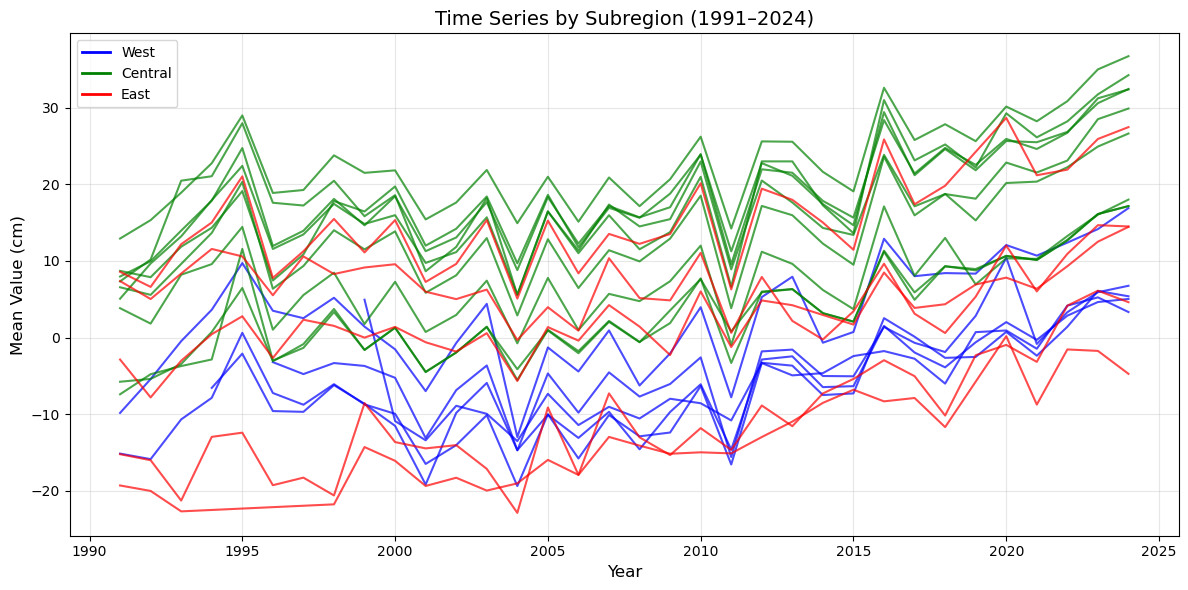

In [7]:
import matplotlib.pyplot as plt

# Filter years 1991–2024
df = combined_df[(combined_df["year"] >= 1991) & (combined_df["year"] <= 2024)]

# Filter only the stations in each region
west_df = df[df["source_file"].isin(west)]
central_df = df[df["source_file"].isin(central)]
east_df = df[df["source_file"].isin(east)]

plt.figure(figsize=(12, 6))

# --- WEST ---
for station, subdf in west_df.groupby("source_file"):
    plt.plot(subdf["year"], subdf["mean_value_NAVD88"], 
             color="blue", alpha=0.7, linewidth=1.5, label="_nolegend_")

# --- CENTRAL ---
for station, subdf in central_df.groupby("source_file"):
    plt.plot(subdf["year"], subdf["mean_value_NAVD88"], 
             color="green", alpha=0.7, linewidth=1.5, label="_nolegend_")

# --- EAST ---
for station, subdf in east_df.groupby("source_file"):
    plt.plot(subdf["year"], subdf["mean_value_NAVD88"], 
             color="red", alpha=0.7, linewidth=1.5, label="_nolegend_")

# Labels and title
plt.xlabel("Year", fontsize=12)
plt.ylabel("Mean Value (cm)", fontsize=12)
plt.title("Time Series by Subregion (1991–2024)", fontsize=14)

# Custom legend for regions
plt.plot([], [], color="blue", linewidth=2, label="West")
plt.plot([], [], color="green", linewidth=2, label="Central")
plt.plot([], [], color="red", linewidth=2, label="East")
plt.legend()

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
### Treat each row independently and calculate the trend #####

test_df = df[(df["year"] >= 2013) & (df["year"] <= 2024)].copy()
test_df["region"] = test_df["source_file"].apply(
    lambda x: "west" if x in west else ("central" if x in central else "east")
)
trends = {}
for region, subdf in test_df.groupby("region"):
    slope, intercept, r_value, p_value, std_err = linregress(subdf["year"], subdf["mean_value_NAVD88"])
    trends[region] = {
        "slope": slope,
        "p_value": p_value,
        "r2": r_value**2
    }

trend_df = pd.DataFrame(trends).T
print(trend_df)

            slope   p_value        r2
central  1.085074  0.000002  0.195189
east     0.066121  0.782994  0.000254
west     0.942689  0.000002  0.322413


In [139]:
### First average and then calculat the trend #####

trends = {}
for region, subdf in test_df.groupby("region"):
    # Aggregate by year: mean across all stations
    yearly_mean = subdf.groupby("year")["mean_value_NAVD88"].mean().reset_index()
    
    slope, intercept, r_value, p_value, std_err = linregress(
        yearly_mean["year"], yearly_mean["mean_value_NAVD88"]
    )
    trends[region] = {
        "slope": slope,
        "p_value": p_value,
        "r2": r_value**2
    }

trend_df = pd.DataFrame(trends).T
print(trend_df)


            slope   p_value        r2
central  1.085074  0.002635  0.612055
east     0.052338  0.871571  0.002743
west     0.942689  0.000709  0.698523


In [141]:
import pandas as pd
from scipy.stats import linregress

# Filter years 2013–2024
test_df = combined_df[(combined_df["year"] >= 2013) & (combined_df["year"] <= 2024)].copy()

# Assign region
def assign_region(station):
    if station in west:
        return "west"
    elif station in central:
        return "central"
    else:
        return "east"

test_df["region"] = test_df["source_file"].apply(assign_region)

# Baseline each station at 2013
baselined_list = []
for station, subdf in test_df.groupby("source_file"):
    subdf = subdf.copy()
    # Pull 2013 value
    start_val = subdf[subdf["year"] == 2013]["mean_value_NAVD88"].values
    if len(start_val) > 0:
        baseline = start_val[0]
        subdf["baseline"] = subdf["mean_value_NAVD88"] - baseline
        baselined_list.append(subdf)

baselined_df = pd.concat(baselined_list)

# Calculate slope per region using baselined values
trends = {}
for region, subdf in baselined_df.groupby("region"):
    # Aggregate by year: mean across stations in the region
    yearly_mean = subdf.groupby("year")["baseline"].mean().reset_index()
    
    slope, intercept, r_value, p_value, std_err = linregress(yearly_mean["year"], yearly_mean["baseline"])
    
    trends[region] = {
        "slope": slope,
        "p_value": p_value,
        "r2": r_value**2
    }

trend_df = pd.DataFrame(trends).T
print("Baselined regression trends (2013-2024):")
print(trend_df)


Baselined regression trends (2013-2024):
            slope   p_value        r2
central  1.085074  0.002635  0.612055
east     0.073652  0.819019  0.005488
west     0.942689  0.000709  0.698523


In [9]:
import pandas as pd
from scipy.stats import linregress

# Filter years 2013–2024
test_df = combined_df[(combined_df["year"] >= 2013) & (combined_df["year"] <= 2024)].copy()

# Assign region
def assign_region(station):
    if station in west:
        return "west"
    elif station in central:
        return "central"
    else:
        return "east"

test_df["region"] = test_df["source_file"].apply(assign_region)

# Subtract station mean instead of 2013 baseline
demeaned_list = []
for station, subdf in test_df.groupby("source_file"):
    subdf = subdf.copy()
    mean_val = subdf["mean_value_NAVD88"].mean()
    subdf["demeaned"] = subdf["mean_value_NAVD88"] - mean_val
    demeaned_list.append(subdf)

demeaned_df = pd.concat(demeaned_list)

# Calculate slope per region using demeaned values
trends = {}
for region, subdf in demeaned_df.groupby("region"):
    # Aggregate by year: mean across stations in the region
    yearly_mean = subdf.groupby("year")["demeaned"].mean().reset_index()
    
    slope, intercept, r_value, p_value, std_err = linregress(yearly_mean["year"], yearly_mean["demeaned"])
    
    trends[region] = {
        "slope": slope,
        "p_value": p_value,
        "r2": r_value**2
    }

trend_df = pd.DataFrame(trends).T
print("Demeaned regression trends (2013–2024):")
print(trend_df)


Demeaned regression trends (2013–2024):
            slope   p_value        r2
central  1.085074  0.002635  0.612055
east     0.100493  0.742259  0.011304
west     0.942689  0.000709  0.698523
